# Figure S2 — Raman density uncertainty

This standalone notebook plots relative uncertainty in Raman-derived vapor-bubble CO$_2$ density. It preserves the source measurements, eligibility rules, and uncertainty calculation used in the earlier workflow.

The notebook is deliberately divided into two visible parts: the shared project setup copied from `00_Setup`, followed by the code used only for Figure S2.

## Public reproduction — start here

This notebook is independent and includes its own plotting setup. The companion `.md` is an internal author note and is **not needed** to run it. Instructions below require no private author notes or previously executed notebook.

### 1. Create a separate Python environment once

The reference workflow uses **Python 3.11** (author run: 3.11.15). Run these commands in a terminal; installation is deliberately not run by scientific cells. On macOS/Linux:

```bash
python3.11 -m venv gp-figures
source gp-figures/bin/activate
python -m pip install numpy==1.26.4 pandas==3.0.5 matplotlib==3.11.1 seaborn==0.13.2 openpyxl==3.1.5 scipy==1.17.1 statsmodels==0.14.6 Pillow==12.3.0 ipython==9.16.0 packaging==26.2 nbformat==5.10.4 nbclient==0.11.0 ipykernel==7.3.0 jupyterlab==4.6.4
python -m ipykernel install --user --name gp-figures --display-name "Glacier Peak figures"
```

On Windows use `py -3.11 -m venv gp-figures` and `gp-figures\Scripts\activate` for the first two commands. Run the remaining commands with that environment active. Select **Glacier Peak figures** as the notebook kernel. These are pinned reference versions, not a request to upgrade an existing environment. The installed-version table later in the notebook is a diagnostic, not an installer.

### 2. Supply the data and choose paths

Keep all three public workbooks in one folder, with these exact filenames:

- `Dechert_S1_AllData.xlsx`
- `Dechert_S2_Standards.xlsx`
- `Dechert_S3_Compilations.xlsx`

Keep this notebook inside its named figure directory beneath `Nov6_AllFigures`. In **Choose one data directory**, set `User_directory = Path('/your/supplemental/data/folder')`, comment out `DATA_DIRECTORY = Dechert_directory`, and uncomment `DATA_DIRECTORY = User_directory`. Those are the only data-path edits for ordinary figures. If the kernel starts elsewhere or the repository folder is renamed, also set `PROJECT_ROOT_OVERRIDE = Path('/your/path/to/Nov6_AllFigures')`. Keep the fixed `FIGURE_FOLDER` value matching this notebook's folder. Missing workbooks/sheets cause an explicit error; there is no fallback to older data.

### 3. Run and check

Open JupyterLab with `python -m jupyterlab`, select the new kernel, then **Restart Kernel and Run All Cells**. Run from the first cell; do not skip setup or calculation cells. All figure outputs are generated as PDF, PNG and SVG in the local figure-output directory. Re-running overwrites those exports; it does not modify the source Excel files. No generated CSV, cached model result or previous notebook run is required.

For matching typography, install **Arial** through a properly licensed system source and restart Python. The journal explicitly permits an equivalent sans serif, and this project uses Arial consistently. The setup requires Arial rather than silently substituting another font and prints the exact resolved font file. Arial is not bundled in this repository. Other fonts can change glyph metrics/layout even when data and calculations match. Reproduction means the same scientific results and configured appearance with the reference dependencies; PDF/SVG metadata dates may differ. Keep existing scientific filters/equations unchanged when adjusting file locations.



### Reproduction check — 26 October 2026

Tested from a separate Python3.11 virtual environment installed from public packages, using copies of this notebook and only the three public supplemental workbooks. Only the documented user data/root path settings were changed for the test. No authorPython environment, companionMarkdown or previous output was required. The shared setup completed successfully. This test used the same macOS system and availableArial fonts; Windows/Linux and other fonts have not been independently tested. PDF/SVG metadata dates may differ.


## 1. Core imports

In [1]:
from pathlib import Path
import sys
import platform
import hashlib
import re
import unicodedata
import warnings
import importlib
from importlib import metadata
from importlib.util import find_spec

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.markers import MarkerStyle
from matplotlib.path import Path as MarkerPath
import seaborn as sns
import openpyxl
from IPython.display import display

print('Python:', sys.version.split()[0])
print('Executable:', sys.executable)

Python: 3.11.15
Executable: /Users/annikadechert/miniforge3/envs/Thermobar/bin/python


## 2. Choose one data directory; keep the supplemental filenames fixed
`Dechert_directory` and `User_directory` are alternative path settings, not new copies of the data. Public users set one folder containing all three workbooks, then select it with `DATA_DIRECTORY = User_directory`. No search or fallback to older data occurs.

In [2]:
Dechert_directory = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20')
User_directory = Path('/replace/with/your/folder/containing/the/three/supplemental/files')

DATA_DIRECTORY = Dechert_directory
# DATA_DIRECTORY = User_directory  # Comment out the Dechert selection above and uncomment this line.

# The kernel should start in Nov6_AllFigures or one of its figure folders.
FIGURE_FOLDER = 'Figure_S02_Density_Uncertainty'  # Change in each standalone figure notebook.
PROJECT_ROOT_OVERRIDE = None  # Public users may set Path('/path/to/Nov6_AllFigures').
if PROJECT_ROOT_OVERRIDE is not None:
    PROJECT_ROOT = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
else:
    project_candidates = [p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if p.name == 'Nov6_AllFigures']
    if not project_candidates:
        raise FileNotFoundError('Start in Nov6_AllFigures or a figure subfolder, or set PROJECT_ROOT_OVERRIDE.')
    PROJECT_ROOT = project_candidates[0]
DATA_DIRECTORY = DATA_DIRECTORY.expanduser().resolve()
CURRENT_FIGURE_DIRECTORY = PROJECT_ROOT / FIGURE_FOLDER
if not DATA_DIRECTORY.is_dir():
    raise FileNotFoundError(f'Selected supplemental-data directory does not exist: {DATA_DIRECTORY}')
if not CURRENT_FIGURE_DIRECTORY.is_dir():
    raise FileNotFoundError(f'Create the intended figure folder first: {CURRENT_FIGURE_DIRECTORY}')
WORKBOOK_PATHS = {
    'S1': DATA_DIRECTORY / 'Dechert_S1_AllData.xlsx',
    'S2': DATA_DIRECTORY / 'Dechert_S2_Standards.xlsx',
    'S3': DATA_DIRECTORY / 'Dechert_S3_Compilations.xlsx',
}
for key, path in WORKBOOK_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f'{key}: required supplemental file not found: {path}')
SOURCE_HASHES_BEFORE = {key: hashlib.sha256(path.read_bytes()).hexdigest() for key, path in WORKBOOK_PATHS.items()}
display(pd.DataFrame([{'supplement': k, 'file': p.name, 'directory': str(p.parent)} for k,p in WORKBOOK_PATHS.items()]))

,supplement,file,directory
0,S1,Dechert_S1_AllData.xlsx,/Users/annikadechert/Library/Mobile Documents/...
1,S2,Dechert_S2_Standards.xlsx,/Users/annikadechert/Library/Mobile Documents/...
2,S3,Dechert_S3_Compilations.xlsx,/Users/annikadechert/Library/Mobile Documents/...


## 3. Publication style
Defaults below follow the April 2026 Science Advances guide and the project decision to use Arial consistently: 8 pt ordinary text, uppercase 9 pt bold panel labels, minimum 6 pt text only when explicitly needed, minimum 0.28 pt visible strokes, white backgrounds, four-sided axes frames, RGB color, and final one- or two-column dimensions. Gridlines are not prohibited by the journal: use light major gridlines when they improve readability, and omit them when they do not. Minor ticks are off by default but may be used deliberately. The PDF is the submission artifact; SVG remains editable and PNG is a 300 dpi preview only.

In [3]:
# Final physical sizes from the April 2026 Science Advances guide.
SINGLE_COLUMN_WIDTH_IN = 3.55
DOUBLE_COLUMN_WIDTH_IN = 7.25
MAXIMUM_INTERMEDIATE_WIDTH_IN = 5.67
MAXIMUM_RECOMMENDED_HEIGHT_IN = 7.8

# Final text and line sizes. Ordinary text defaults to 8 pt.
BASE_TEXT_SIZE_PT = 8.0
AXIS_LABEL_SIZE_PT = 8.0
TITLE_SIZE_PT = 8.0
TICK_LABEL_SIZE_PT = 8.0
LEGEND_SIZE_PT = 8.0
LEGEND_TITLE_SIZE_PT = 8.0
ANNOTATION_SIZE_PT = 8.0
MINIMUM_TEXT_SIZE_PT = 6.0
PANEL_LABEL_SIZE_PT = 9.0
MINIMUM_LINE_WIDTH_PT = 0.28

# Arial is the project font. Stop rather than silently substituting another font.
PUBLICATION_FONT = 'Arial'
INSTALLED_FONT_NAMES = {entry.name for entry in font_manager.fontManager.ttflist}
if PUBLICATION_FONT not in INSTALLED_FONT_NAMES:
    raise RuntimeError('Arial is required. Install a licensed Arial font and restart Python.')
PUBLICATION_FONT_PATH = font_manager.findfont(PUBLICATION_FONT, fallback_to_default=False)

# These settings apply directly to every plot created after this cell.
mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': [PUBLICATION_FONT],
    'font.size': BASE_TEXT_SIZE_PT,
    'axes.labelsize': AXIS_LABEL_SIZE_PT,
    'axes.titlesize': TITLE_SIZE_PT,
    'xtick.labelsize': TICK_LABEL_SIZE_PT,
    'ytick.labelsize': TICK_LABEL_SIZE_PT,
    'legend.fontsize': LEGEND_SIZE_PT,
    'legend.title_fontsize': LEGEND_TITLE_SIZE_PT,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.grid': False,
    'axes.spines.top': True,
    'axes.spines.right': True,
    'axes.linewidth': 0.5,
    'lines.linewidth': 0.75,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.minor.visible': False,
    'ytick.minor.visible': False,
    'savefig.dpi': 300,
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'mathtext.fontset': 'custom',
    'mathtext.rm': PUBLICATION_FONT,
    'mathtext.it': f'{PUBLICATION_FONT}:italic',
    'mathtext.bf': f'{PUBLICATION_FONT}:bold',
    'mathtext.bfit': f'{PUBLICATION_FONT}:bold:italic',
    'mathtext.fallback': 'stix',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
})
sns.set_palette('colorblind')

print(f'Publication font: {PUBLICATION_FONT}')
print(f'Resolved font file: {PUBLICATION_FONT_PATH}')
print(f'Column widths: {SINGLE_COLUMN_WIDTH_IN} in and {DOUBLE_COLUMN_WIDTH_IN} in')
print(f'Maximum recommended height: {MAXIMUM_RECOMMENDED_HEIGHT_IN} in')

Publication font: Arial
Resolved font file: /System/Library/Fonts/Supplemental/Arial.ttf
Column widths: 3.55 in and 7.25 in
Maximum recommended height: 7.8 in


In [4]:
# This notebook intentionally defines no custom functions.
# Each figure notebook will contain its own explicit publication-formatting cell after plotting.
# That cell will visibly perform these steps in order:
# 1. Set the figure and axes backgrounds to white.
# 2. Choose gridlines deliberately and keep them light; minor ticks are off by default.
# 3. Set ordinary text to Arial 8 pt unless a clearly documented 6-7 pt exception is needed.
# 4. Add separate uppercase panel labels at 9 pt bold.
# 5. Raise every positive visible stroke below 0.28 pt to 0.28 pt.
# 6. Check the physical width and height.
# 7. Draw the canvas and inspect text sizes, clipping, and legend overlap.
# 8. Export PDF, PNG, and SVG with direct savefig calls.
# 9. Treat PDF as the submission file, PNG as preview-only, and SVG as the editable archive.

PUBLICATION_FORMATTING_STEPS = [
    'White figure and axes backgrounds',
    'Light major gridlines only when they improve readability',
    'Minor ticks off by default unless deliberately needed',
    'Arial ordinary text at 8 pt by default',
    'Ordinary text never below 6 pt',
    'Separate uppercase panel labels at 9 pt bold',
    'Visible strokes at least 0.28 pt',
    'Permitted final physical dimensions',
    'No figure-level title in the image',
    'No clipping or overlapping legend blocks',
    'RGB vector PDF submission file',
]
display(pd.Series(PUBLICATION_FORMATTING_STEPS, name='Explicit steps copied into each figure notebook'))

0                     White figure and axes backgrounds
1     Light major gridlines only when they improve r...
2     Minor ticks off by default unless deliberately...
3                Arial ordinary text at 8 pt by default
4                        Ordinary text never below 6 pt
5          Separate uppercase panel labels at 9 pt bold
6                      Visible strokes at least 0.28 pt
7                   Permitted final physical dimensions
8                    No figure-level title in the image
9              No clipping or overlapping legend blocks
10                       RGB vector PDF submission file
Name: Explicit steps copied into each figure notebook, dtype: str

## 4. Approved colors, semantic markers, and lookups
Color represents sample/unit except the explicit bright-green high-Al₂O₃ highlight. Main B warm and G cool; dark mingled populations remain gray/black. Your glass = `x`; Kuehn = `+`; dacite vein = diamond; whole rock = star. Backup minerals do not reuse those symbols.

In [5]:
# Editable project sample configuration.
SAMPLE_COLORS = {
    "74D": "#F4A261",
    "74A": "#D55E00",
    "75": "#56B4E9",
    "76A": "#0072B2",
}
SAMPLE_LABELS = {
    "74D": "B Middle",
    "74A": "B Base",
    "75": "G Top",
    "76A": "G Middle",
}
DEFAULT_SAMPLE_COLOR = "#7A7A7A"
KUEHN_COLORS = {"B": "#D4A017", "G": "#006D77"}
DACITE_VEIN_COLOR = "#9E2A4F"
KUEHN_GLASS_MARKER = "+"
DACITE_VEIN_MARKER = "D"

MINGLED_TERMINOLOGY = {
    "felsic": "light",
    "mafic": "dark",
    "light": "light",
    "dark": "dark",
}
MINGLED_SAMPLE_COLORS = {
    "B light": "#EE3377",
    "B dark": "#808080",
    "G light": "#66C2C2",
    "G dark": "#000000",
}
MINGLED_SAMPLE_LABELS = {key: key for key in MINGLED_SAMPLE_COLORS}

PHASE_STYLES = {
    "plag": {"label": "Plagioclase", "marker": "o"},
    "pxy": {"label": "Pyroxene", "marker": "s"},
    "opx": {"label": "Pyroxene", "marker": "s"},
}
HOST_MARKERS = {
    "Plagioclase": "o",
    "Pyroxene": "s",
    "Amphibole": "^",
    "Olivine": "p",
    "Quartz": "H",
    "Biotite": "v",
    "Apatite": "<",
    "Host not reported": "h",
}
MATRIX_GLASS_MARKER = "x"
MATRIX_GLASS_ALIASES = {
    "mtx",
    "matrix glass",
    "groundmass glass",
    "interstitial glass",
}
WHOLE_ROCK_STYLE = {
    "label": "Whole rock",
    "marker": "*",
    "facecolor": "#B0B0B0",
    "edgecolor": "black",
}

HIGH_AL2O3_AMPHIBOLE_IDENTIFIERS = (
    "74A2_amph 12",
    "74A2_amph 7",
    "74A2 px14",
)
HIGH_AL2O3_AMPHIBOLE_COLOR = "#39FF14"
DEFAULT_AMPHIBOLE_COLOR = "#777777"

VOLCANO_COLOR_OVERRIDES = {
    "Lassen": "#007C83",
    "Mazama": "#D97706",
    "Mount St. Helens": "#6D5AAE",
    "Mt Hood": "#3B6FB6",
    "Glacier Peak": "#FF1493",
}


# Plain lookup tables replace the former normalization and styling functions.
# Each figure notebook will show its own string cleaning and mapping directly.
HOST_LABEL_ALIASES = {
    'plag': 'Plagioclase', 'plagioclase': 'Plagioclase',
    'px': 'Pyroxene', 'pxy': 'Pyroxene', 'opx': 'Pyroxene', 'cpx': 'Pyroxene',
    'pyroxene': 'Pyroxene', 'amph': 'Amphibole', 'amphibole': 'Amphibole',
    'ol': 'Olivine', 'olivine': 'Olivine', 'qtz': 'Quartz', 'quartz': 'Quartz',
    'bt': 'Biotite', 'biotite': 'Biotite', 'ap': 'Apatite', 'apatite': 'Apatite',
    '': 'Host not reported', 'unknown': 'Host not reported',
    'not reported': 'Host not reported', 'host not reported': 'Host not reported',
}
METHOD_LABEL_ALIASES = {
    'sims': 'SIMS', 'ftir': 'FTIR', 'icp-ms': 'ICP-MS',
    'emp': 'EMP/EPMA', 'epma': 'EMP/EPMA', 'emp/epma': 'EMP/EPMA',
}
print('Palette, marker, host-label, and method-label lookup tables are ready.')

Palette, marker, host-label, and method-label lookup tables are ready.


## 5. Marker geometry — final approved TAS preview
Dimensions are in points. Baseline width/height 6; dacite 6.9; Kuehn 6.9; whole rock 7.92. These are intentionally different to reproduce the approved visual balance. Your `x` and Kuehn `+` are filled custom paths: Kuehn arm width stays 1.92 pt as its span increases. Use **`SCATTER_STYLES[category]`**, not marker letters alone, to retain this appearance. Small outlined filled symbols include a 0.28 pt edge. Custom shapes have width and height normalized independently, as in the approved preview.

No custom functions are defined. Style settings, lookups, cleanup, checks, and export commands are written as direct sequential code so every action remains visible and editable. There are no hidden scientific calculations or source-data mutations.

In [6]:
MARKER_SPANS_PT = {'plag': 6.0, 'pxy': 6.0, 'amph': 6.0, 'matrix_glass': 6.0,
                   'kuehn_glass': 6.9, 'dacite_vein': 6.9, 'whole_rock': 7.92}
MARKER_LETTERS = {'plag': 'o', 'pxy': 's', 'amph': '^', 'matrix_glass': 'x',
                  'kuehn_glass': '+', 'dacite_vein': 'D', 'whole_rock': '*'}
MARKER_PATHS = {}
SCATTER_STYLES = {}
MARKER_AUDIT_ROWS = []
for category, marker in MARKER_LETTERS.items():
    span = MARKER_SPANS_PT[category]
    cross = marker in {'x', '+'}
    if cross:
        relative_arm_width = 0.14 if marker == 'x' else 0.32 / 1.15
        half_arm = relative_arm_width / 2
        vertices = np.array([[-half_arm,-.5],[half_arm,-.5],[half_arm,-half_arm],[.5,-half_arm],
                             [.5,half_arm],[half_arm,half_arm],[half_arm,.5],[-half_arm,.5],
                             [-half_arm,half_arm],[-.5,half_arm],[-.5,-half_arm],
                             [-half_arm,-half_arm],[-half_arm,-.5]])
        if marker == 'x':
            vertices = vertices @ np.array([[1,-1],[1,1]]) / np.sqrt(2)
        path = MarkerPath(vertices, closed=True)
    else:
        standard_marker = MarkerStyle(marker)
        path = standard_marker.get_path().transformed(standard_marker.get_transform())
    bounds = path.get_extents()
    vertices = path.vertices.copy()
    vertices[:,0] = (vertices[:,0] - (bounds.x0 + bounds.x1)/2) / bounds.width
    vertices[:,1] = (vertices[:,1] - (bounds.y0 + bounds.y1)/2) / bounds.height
    normalized_path = MarkerPath(vertices, path.codes)
    edge_width = 0.0 if cross else 0.28
    MARKER_PATHS[category] = normalized_path
    SCATTER_STYLES[category] = {'marker': normalized_path, 's': (span-edge_width)**2,
                               'linewidths': edge_width, 'edgecolors': 'none' if cross else 'black'}
    MARKER_AUDIT_ROWS.append({'category': category, 'marker': marker, 'span_pt': span,
                              'scatter_s': (span-edge_width)**2, 'outline_pt': edge_width})
    assert np.allclose(normalized_path.get_extents().size, [1,1])
MARKER_AUDIT = pd.DataFrame(MARKER_AUDIT_ROWS)
display(MARKER_AUDIT)
assert np.isclose(MARKER_SPANS_PT['kuehn_glass'] * (0.32/1.15), 1.92)
# Example: ax.scatter(x, y, c=KUEHN_COLORS['G'], **SCATTER_STYLES['kuehn_glass'])
# Alpha and drawing order remain explicit figure-level choices; this setup does not change them.

,category,marker,span_pt,scatter_s,outline_pt
0,plag,o,6.00,32.7184,0.28
1,pxy,s,6.00,32.7184,0.28
2,amph,^,6.00,32.7184,0.28
3,matrix_glass,x,6.00,36.0000,0.00
4,kuehn_glass,+,6.90,47.6100,0.00
5,dacite_vein,D,6.90,43.8244,0.28
6,whole_rock,*,7.92,58.3696,0.28


### Two distinct legend keys: Samples and Data Type
**Samples** explains colors; **Data Type** explains shapes. Include only populations present in the figure. Use explicit host labels for melt-inclusion plots and mineral labels for mineral-chemistry plots; never combine them into an ambiguous slash label. `MI` means melt inclusion and must be defined in the caption. The high-Al₂O₃ green is a population highlight, so its handle is separate from the Samples list and is added only where relevant. Figure-specific placement must be checked against plotted points.

In [7]:
SAMPLE_LEGEND_TITLE = 'Samples'
DATA_TYPE_LEGEND_TITLE = 'Data Type'
KUEHN_LABELS = {unit: f'{unit} Kuehn' for unit in KUEHN_COLORS}
DACITE_VEIN_LABEL = 'B Trinity Dacite Vein'

# Select the correct scientific context in each figure notebook.
DATA_TYPE_LABELS_MI = {
    'plag': 'Plagioclase-hosted MI', 'pxy': 'Pyroxene-hosted MI',
    'amph': 'Amphibole-hosted MI', 'matrix_glass': 'Matrix glass (this study)',
    'kuehn_glass': 'Distal glass (Kuehn et al., 2009)',
    'dacite_vein': 'Vein glass', 'whole_rock': 'Whole rock',
}
DATA_TYPE_LABELS_MINERALS = {**DATA_TYPE_LABELS_MI,
    'plag': 'Plagioclase', 'pxy': 'Pyroxene', 'amph': 'Amphibole'}
DATA_TYPE_LABELS_HOSTS = {**DATA_TYPE_LABELS_MI,
    'plag': 'Plagioclase MI host', 'pxy': 'Pyroxene MI host', 'amph': 'Amphibole MI host'}
LEGEND_CONTEXT = 'melt_inclusions'  # 'mi_hosts' for verified hosts; 'minerals' for general crystals/transects.
if LEGEND_CONTEXT not in {'melt_inclusions', 'mi_hosts', 'minerals'}:
    raise ValueError('Choose an explicit legend context.')
LEGEND_LABELS_BY_CONTEXT = {'melt_inclusions': DATA_TYPE_LABELS_MI,
                            'mi_hosts': DATA_TYPE_LABELS_HOSTS, 'minerals': DATA_TYPE_LABELS_MINERALS}
SYMBOL_LEGEND_LABELS = LEGEND_LABELS_BY_CONTEXT[LEGEND_CONTEXT]
SYMBOL_LEGEND_HANDLES = {}
for category, style in SCATTER_STYLES.items():
    SYMBOL_LEGEND_HANDLES[category] = Line2D([0],[0],linestyle='none',marker=style['marker'],
        markersize=np.sqrt(style['s']),markerfacecolor='0.35',
        markeredgecolor=style['edgecolors'],markeredgewidth=style['linewidths'],
        label=SYMBOL_LEGEND_LABELS[category])
SAMPLE_LEGEND_HANDLES = {key: Patch(facecolor=color,edgecolor='none',label=SAMPLE_LABELS[key])
                         for key,color in SAMPLE_COLORS.items()}
SAMPLE_LEGEND_HANDLES.update({key: Patch(facecolor=color,edgecolor='none',label=f'{key} mingled glass')
                              for key,color in MINGLED_SAMPLE_COLORS.items()})
SAMPLE_LEGEND_HANDLES.update({f'Kuehn {unit}': Patch(facecolor=color,edgecolor='none',label=KUEHN_LABELS[unit])
                              for unit,color in KUEHN_COLORS.items()})
SAMPLE_LEGEND_HANDLES['vein'] = Patch(facecolor=DACITE_VEIN_COLOR,edgecolor='none',label=DACITE_VEIN_LABEL)
COLOR_LEGEND_HANDLES = list(SAMPLE_LEGEND_HANDLES.values())
HIGH_AL_LEGEND_HANDLE = Patch(facecolor=HIGH_AL2O3_AMPHIBOLE_COLOR,edgecolor='none',label='High-Al$_2$O$_3$ amphibole population')

# In each figure, explicitly select only the groups and data types actually plotted:
# samples_legend = ax.legend(handles=[SAMPLE_LEGEND_HANDLES[k] for k in ['74D','74A','75','76A']],
#                            title=SAMPLE_LEGEND_TITLE, loc='upper left')
# ax.add_artist(samples_legend)  # Preserve the first legend when adding the second.
# ax.legend(handles=[SYMBOL_LEGEND_HANDLES[k] for k in ['plag','pxy','whole_rock']],
#           title=DATA_TYPE_LEGEND_TITLE, loc='lower left')
# Add HIGH_AL_LEGEND_HANDLE as a separate population-highlight key only if present.

In [8]:
# Legends are built explicitly inside each figure notebook.
# Do not collect, merge, move, or rename legends automatically.
# The figure notebook must list the exact handles, labels, title, location, and column count.
# This keeps the published legend visible and editable next to the plotting code.


## 6. Exact supplemental sheet map
S1/S3 sheets use their first row as headers; S2 contains multiple table blocks and is read with `header=None` to preserve their locations. Dictionaries remain separate. No legacy variable aliases pretend the new columns are the old schema. Work on `.copy()` objects in figure cells. The row count includes all rows pandas reads, not a claim about valid analyses.

In [9]:
EXPECTED_SHEETS = {'S1': ['MI_Hosts_Plag_Pxy', 'MI_Hosts_Plag_Pxy_Dictionary', 'TE_MI_Replicates', 'MI_Amph', 'MI_Amph_Dict', 'Transects', 'Transects_Dictionary', 'Mingled_Matrix_Glass', 'Mingled_Matrix_Glass_Dictionary', 'Mingled_Minerals', 'Mingled_Minerals_Dictionary', 'Dacite_Vein', 'Dacite_Vein_Dictionary', 'Whole_Rock', 'Whole_Rock_Dictionary'], 'S2': ['SEM', 'LA-ICP-MS', 'SIMS', 'Whole Rock'], 'S3': ['Wieser2023_MI_Compilation', 'GEOROC_GlobalDacites', 'Kuehn2009', 'Hoblitt_1987', 'GVP 2024']}
for supplement, expected in EXPECTED_SHEETS.items():
    with pd.ExcelFile(WORKBOOK_PATHS[supplement]) as workbook:
        if workbook.sheet_names != expected:
            raise ValueError(f'{supplement}: worksheet inventory/order changed; inspect before continuing. Found {workbook.sheet_names}')

In [10]:
mi_hosts_plag_pxy = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='MI_Hosts_Plag_Pxy', header=0)
mi_hosts_dictionary = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='MI_Hosts_Plag_Pxy_Dictionary', header=0)
te_mi_replicates = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='TE_MI_Replicates', header=0)
mi_amph = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='MI_Amph', header=0)
mi_amph_dictionary = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='MI_Amph_Dict', header=0)
transects = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Transects', header=0)
transects_dictionary = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Transects_Dictionary', header=0)
mingled_matrix_glass = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Mingled_Matrix_Glass', header=0)
mingled_matrix_glass_dictionary = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Mingled_Matrix_Glass_Dictionary', header=0)
mingled_minerals = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Mingled_Minerals', header=0)
mingled_minerals_dictionary = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Mingled_Minerals_Dictionary', header=0)
dacite_vein = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Dacite_Vein', header=0)
dacite_vein_dictionary = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Dacite_Vein_Dictionary', header=0)
whole_rock = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Whole_Rock', header=0)
whole_rock_dictionary = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Whole_Rock_Dictionary', header=0)

In [11]:
standards_sem_raw = pd.read_excel(WORKBOOK_PATHS['S2'], sheet_name='SEM', header=None)
standards_la_icp_ms_raw = pd.read_excel(WORKBOOK_PATHS['S2'], sheet_name='LA-ICP-MS', header=None)
standards_sims_raw = pd.read_excel(WORKBOOK_PATHS['S2'], sheet_name='SIMS', header=None)
standards_whole_rock_raw = pd.read_excel(WORKBOOK_PATHS['S2'], sheet_name='Whole Rock', header=None)

In [12]:
wieser2023_mi_compilation = pd.read_excel(WORKBOOK_PATHS['S3'], sheet_name='Wieser2023_MI_Compilation', header=0)
georoc_global_dacites = pd.read_excel(WORKBOOK_PATHS['S3'], sheet_name='GEOROC_GlobalDacites', header=0)
kuehn2009 = pd.read_excel(WORKBOOK_PATHS['S3'], sheet_name='Kuehn2009', header=0)
hoblitt1987 = pd.read_excel(WORKBOOK_PATHS['S3'], sheet_name='Hoblitt_1987', header=0)
gvp2024 = pd.read_excel(WORKBOOK_PATHS['S3'], sheet_name='GVP 2024', header=0)


In [13]:
SHEET_MAP = [('S1', 'MI_Hosts_Plag_Pxy', 'mi_hosts_plag_pxy'), ('S1', 'MI_Hosts_Plag_Pxy_Dictionary', 'mi_hosts_dictionary'), ('S1', 'TE_MI_Replicates', 'te_mi_replicates'), ('S1', 'MI_Amph', 'mi_amph'), ('S1', 'MI_Amph_Dict', 'mi_amph_dictionary'), ('S1', 'Transects', 'transects'), ('S1', 'Transects_Dictionary', 'transects_dictionary'), ('S1', 'Mingled_Matrix_Glass', 'mingled_matrix_glass'), ('S1', 'Mingled_Matrix_Glass_Dictionary', 'mingled_matrix_glass_dictionary'), ('S1', 'Mingled_Minerals', 'mingled_minerals'), ('S1', 'Mingled_Minerals_Dictionary', 'mingled_minerals_dictionary'), ('S1', 'Dacite_Vein', 'dacite_vein'), ('S1', 'Dacite_Vein_Dictionary', 'dacite_vein_dictionary'), ('S1', 'Whole_Rock', 'whole_rock'), ('S1', 'Whole_Rock_Dictionary', 'whole_rock_dictionary'), ('S2', 'SEM', 'standards_sem_raw'), ('S2', 'LA-ICP-MS', 'standards_la_icp_ms_raw'), ('S2', 'SIMS', 'standards_sims_raw'), ('S2', 'Whole Rock', 'standards_whole_rock_raw'), ('S3', 'Wieser2023_MI_Compilation', 'wieser2023_mi_compilation'), ('S3', 'GEOROC_GlobalDacites', 'georoc_global_dacites'), ('S3', 'Kuehn2009', 'kuehn2009'), ('S3', 'Hoblitt_1987', 'hoblitt1987'), ('S3', 'GVP 2024', 'gvp2024')]
DATAFRAME_VARIABLES = {name: globals()[name] for supplement, sheet, name in SHEET_MAP}
WORKBOOK_DATA = {key: {} for key in WORKBOOK_PATHS}
metadata_rows = []
for supplement, sheet, name in SHEET_MAP:
    frame = DATAFRAME_VARIABLES[name]
    WORKBOOK_DATA[supplement][sheet] = frame
    metadata_rows.append({'supplement': supplement, 'workbook': WORKBOOK_PATHS[supplement].name,
                          'sheet': sheet, 'variable': name, 'rows': len(frame), 'columns': len(frame.columns),
                          'header': None if supplement == 'S2' else 0})
SHEET_METADATA = pd.DataFrame(metadata_rows)
SOURCE_FRAME_HASHES = {name: hashlib.sha256(pd.util.hash_pandas_object(frame, index=True).values.tobytes()).hexdigest()
                       for name,frame in DATAFRAME_VARIABLES.items()}
assert len(DATAFRAME_VARIABLES) == 24
assert len(set(DATAFRAME_VARIABLES)) == len(SHEET_MAP)
display(SHEET_METADATA)

,supplement,workbook,sheet,variable,rows,columns,header
0,S1,Dechert_S1_AllData.xlsx,MI_Hosts_Plag_Pxy,mi_hosts_plag_pxy,212,817,0.0
1,S1,Dechert_S1_AllData.xlsx,MI_Hosts_Plag_Pxy_Dictionary,mi_hosts_dictionary,833,4,0.0
2,S1,Dechert_S1_AllData.xlsx,TE_MI_Replicates,te_mi_replicates,212,154,0.0
3,S1,Dechert_S1_AllData.xlsx,MI_Amph,mi_amph,5,26,0.0
4,S1,Dechert_S1_AllData.xlsx,MI_Amph_Dict,mi_amph_dictionary,8,2,0.0
5,S1,Dechert_S1_AllData.xlsx,Transects,transects,14863,31,0.0
6,S1,Dechert_S1_AllData.xlsx,Transects_Dictionary,transects_dictionary,31,2,0.0
7,S1,Dechert_S1_AllData.xlsx,Mingled_Matrix_Glass,mingled_matrix_glass,183,31,0.0
8,S1,Dechert_S1_AllData.xlsx,Mingled_Matrix_Glass_Dictionary,mingled_matrix_glass_dictionary,31,2,0.0
9,S1,Dechert_S1_AllData.xlsx,Mingled_Minerals,mingled_minerals,733,42,0.0


## 7. Method-specific eligibility — no source edits
`Discard_SIMS` is a case-insensitive Yes exclusion. The supplied `Plot_Eligible_SIMS`/`Plot_Eligible_SEM_Glass` fields are recorded independently; this setup does not silently combine distinct QC rules. Figure notebooks must explicitly choose and document the applicable eligibility mask, then apply analyte-specific nonmissingness. No global dropna, zero filling, renaming, or inference of B/G from unknown identifiers.

In [14]:
SIMS_DISCARD_MASK = {}
SIMS_PLOTTING_VIEWS = {}
PLOTTING_ELIGIBILITY_MASKS = {}
ELIGIBILITY_FIELD_AUDIT = []
for name, frame in DATAFRAME_VARIABLES.items():
    PLOTTING_ELIGIBILITY_MASKS[name] = {}
    if 'Discard_SIMS' in frame.columns:
        discarded = frame['Discard_SIMS'].astype('string').str.strip().str.casefold().eq('yes').fillna(False)
        SIMS_DISCARD_MASK[name] = discarded
        SIMS_PLOTTING_VIEWS[name] = {analyte: frame.loc[~discarded].copy() for analyte in ['H2O','CO2','F','C']}
        PLOTTING_ELIGIBILITY_MASKS[name]['not_discarded_SIMS'] = ~discarded
        ELIGIBILITY_FIELD_AUDIT.append({'variable': name, 'field': 'Discard_SIMS', 'source_rows': len(frame), 'excluded_yes': int(discarded.sum())})
    for field in ['Plot_Eligible_SIMS', 'Plot_Eligible_SEM_Glass']:
        if field in frame.columns:
            normalized = frame[field].astype('string').str.strip().str.casefold()
            accepted = normalized.isin(['true','yes','1','1.0'])
            PLOTTING_ELIGIBILITY_MASKS[name][field] = accepted
            ELIGIBILITY_FIELD_AUDIT.append({'variable': name, 'field': field, 'source_rows': len(frame),
                                            'eligible_explicit_true': int(accepted.sum()),
                                            'source_value_counts': repr(frame[field].value_counts(dropna=False).to_dict())})
display(pd.DataFrame(ELIGIBILITY_FIELD_AUDIT))

,variable,field,source_rows,excluded_yes,eligible_explicit_true,source_value_counts
0,mi_hosts_plag_pxy,Discard_SIMS,212,13.0,NaN,NaN
1,mi_hosts_plag_pxy,Plot_Eligible_SIMS,212,NaN,199.0,"{True: 199, False: 13}"
2,mi_hosts_plag_pxy,Plot_Eligible_SEM_Glass,212,NaN,208.0,"{True: 208, False: 4}"


In [15]:
# SEM eligibility is independent of SIMS/TE. Reasons begin with Yes, not only exact Yes.
SEM_GLASS_DISCARD_MASK = {}
SEM_GLASS_PLOTTING_VIEWS = {}
for name, frame in DATAFRAME_VARIABLES.items():
    if 'Discard_SEMGlass_Raw' in frame.columns:
        mask = frame['Discard_SEMGlass_Raw'].astype('string').str.strip().str.casefold().str.startswith('yes', na=False)
        SEM_GLASS_DISCARD_MASK[name] = mask
        SEM_GLASS_PLOTTING_VIEWS[name] = frame.loc[~mask].copy()
        PLOTTING_ELIGIBILITY_MASKS[name]['not_discarded_SEM_glass'] = ~mask
        if 'Plot_Eligible_SEM_Glass' in frame.columns:
            supplied = frame['Plot_Eligible_SEM_Glass'].astype('string').str.strip().str.casefold().isin(['true','yes','1','1.0'])
            assert np.array_equal(supplied.to_numpy(dtype=bool), (~mask).to_numpy(dtype=bool)), 'SEM flag and supplied eligibility disagree; inspect source.'
SEM_DISCARDED_IDS = set(mi_hosts_plag_pxy.loc[SEM_GLASS_DISCARD_MASK['mi_hosts_plag_pxy'], 'base_name'])
print('SEM-discarded inclusions:', sorted(SEM_DISCARDED_IDS))
# Author instruction: exclude these IDs from saturation-pressure plots too; retain independent SIMS/TE eligibility.

SEM-discarded inclusions: ['74A_C23_MI3', '74A_C6_MI1', '74D_C48_MI1', '76A_C31_MI1']


## 8. Installed versions and optional scientific imports
Versions below describe this run, not the historical versions used to produce every workbook column. No installs, upgrades, model calculations, network downloads, or compatibility patches run here. Keep required model imports enabled only in the figures that actually use them; failure then stops that figure explicitly.

In [16]:
PACKAGE_MODULES = {'numpy':'numpy','pandas':'pandas','matplotlib':'matplotlib','seaborn':'seaborn',
 'openpyxl':'openpyxl','scipy':'scipy','statsmodels':'statsmodels','Pillow':'PIL','IPython':'IPython',
 'packaging':'packaging','Thermobar':'Thermobar','VESIcal':'VESIcal','PetThermoTools':'petthermotools',
 'mineralML':'mineralML','DiadFit':'DiadFit','densityx':'densityx','tasplot':'tasplot',
 'nbformat':'nbformat','nbclient':'nbclient','ipykernel':'ipykernel','torch':'torch','scikit-learn':'sklearn'}
version_rows = []
for distribution, module in PACKAGE_MODULES.items():
    try:
        installed = metadata.version(distribution)
    except metadata.PackageNotFoundError:
        installed = 'NOT INSTALLED'
    spec = find_spec(module)
    version_rows.append({'distribution': distribution, 'module': module, 'installed_version': installed,
                         'module_located': spec is not None})
PACKAGE_VERSIONS = pd.DataFrame(version_rows)
display(PACKAGE_VERSIONS)
print('Platform:', platform.platform())

,distribution,module,installed_version,module_located
0,numpy,numpy,1.26.4,True
1,pandas,pandas,3.0.5,True
2,matplotlib,matplotlib,3.11.1,True
3,seaborn,seaborn,0.13.2,True
4,openpyxl,openpyxl,3.1.5,True
5,scipy,scipy,1.17.1,True
6,statsmodels,statsmodels,0.14.6,True
7,Pillow,PIL,12.3.0,True
8,IPython,IPython,9.16.0,True
9,packaging,packaging,26.2,True


Platform: macOS-26.6.2-arm64-arm-64bit


In [17]:
# Turn on only the libraries needed for the figure below this setup.
USE_SCIPY = False
USE_STATSMODELS = False
USE_PILLOW = False
USE_THERMOBAR = False
USE_VESICAL = False
USE_PETTHERMOTOOLS = False
USE_MINERALML = False
USE_DIADFIT = False
USE_DENSITYX = False
USE_TASPLOT = False

if USE_SCIPY:
    from scipy import stats, optimize
if USE_STATSMODELS:
    import statsmodels.api as sm
    import statsmodels.formula.api as smf
if USE_PILLOW:
    from PIL import Image
if USE_THERMOBAR:
    import Thermobar as pt
    import Thermobar.core as tb_core
    import Thermobar.amphibole as tb_amphibole
if USE_VESICAL:
    import VESIcal as vesical
if USE_PETTHERMOTOOLS:
    import petthermotools as ptt
if USE_MINERALML:
    import mineralML as mm
if USE_DIADFIT:
    import DiadFit as pf
if USE_DENSITYX:
    import densityx
if USE_TASPLOT:
    import tasplot

### Software references for this standalone notebook

The installed-version table above describes the execution environment. Cite the software and underlying scientific models actually used in this figure; importing a package or plotting previously calculated results does not establish a new model calculation. The private companion Markdown is not required to run this notebook.

| Software | Reference / authoritative guidance |
|---|---|
| Thermobar | Wieser et al. (2022), *Volcanica* 5, 349–384. [DOI](https://doi.org/10.30909/vol.05.02.349384). Cite the calibration equations used as well. |
| VESIcal | Iacovino et al. (2021), Part I, [DOI](https://doi.org/10.1029/2020EA001584); Wieser et al. (2022), Part II, [DOI](https://doi.org/10.1029/2021EA001932). Include the specific solubility-model reference. |
| PetThermoTools | Gleeson et al. (2026), *PetThermoTools: a fast, flexible, and accessible Python3 package for performing thermodynamic calculations*, *Volcanica*. [DOI](https://doi.org/10.30909/vol/lepa7012). Cite the actual engine/model separately. |
| mineralML | Shi et al. (2026), *mineralML: Leveraging Machine Learning for Probabilistic Mineral Classification*. [DOI](https://doi.org/10.31223/X53J2M); [official guidance](https://mineralml.readthedocs.io/en/stable/introduction.html). |
| DiadFit | Wieser and DeVitre (2024), *Volcanica* 7, 335–359. [DOI](https://doi.org/10.30909/vol.07.01.335359). |
| DensityX | Iacovino and Till (2019), *Volcanica* 2, 1–10. [DOI](https://doi.org/10.30909/vol.02.01.0110). |
| NumPy | Harris et al. (2020), *Array programming with NumPy*. [Official guidance](https://numpy.org/citing-numpy/). |
| pandas | McKinney (2010), *Data Structures for Statistical Computing in Python*. [Official guidance](https://pandas.pydata.org/about/citing.html). |
| Matplotlib | Hunter (2007), *Matplotlib: A 2D Graphics Environment*. [Official guidance](https://matplotlib.org/stable/users/project/citing.html). |
| SciPy | Virtanen et al. (2020), *SciPy 1.0: Fundamental Algorithms for Scientific Computing in Python*. [Official guidance](https://scipy.org/citing-scipy/). |
| statsmodels | Seabold and Perktold (2010), *Statsmodels: Econometric and statistical modeling with Python*, Proceedings of the 9th Python in Science Conference. [Official guidance](https://www.statsmodels.org/stable/index.html#citation). |
| tasplot | Installed implementation credits Stevenson and Cortés (2015) and explicitly attributes TAS fields to Le Maitre (2002), *Igneous Rocks: A Classification and Glossary of Terms*, second edition, Cambridge University Press. [Book](https://www.cambridge.org/core/books/igneous-rocks-a-classification-and-glossary-of-terms/7F458E82BF81BF6A011CEA0D41DE9311). No unverified software DOI is assigned. |

Helper-library versions (including openpyxl, Pillow, IPython, Jupyter, packaging and plotting utilities) are recorded in the environment table. Historical versions used for stored workbook results are not inferred from this run.


## 9. Direct export settings and final compliance boundary
The vector PDF is the submission artifact for notebook-generated graphs. The 300 dpi PNG is a preview only and is not compliant as raster line art; if a graph must be submitted as raster line art, export it separately at 1200 dpi. SVG is an editable archive. Static Illustrator/image composites require their own final checks for RGB color, 300 dpi embedded photographs at final size, 1200 dpi raster line art, accepted TIFF/JPEG/PDF/AI format, permissions, and exact manuscript matching. No scientific data files are written.

In [18]:
EXPORT_DPI = 300  # preview PNG and any embedded raster in the vector PDF
LINE_ART_DPI = 1200
MAX_FILE_SIZE_MB = 25
COMPRESSION_RECOMMENDED_ABOVE_MB = 10
PDF_FORMAT = 'pdf'
PNG_FORMAT = 'png'
SVG_FORMAT = 'svg'

PUBLICATION_MANUAL_CHECKLIST = {
    'text': 'Sentence case; SI units in parentheses; variables italic or plain Greek; leading zeros; significant digits only.',
    'panels': 'Logical left-to-right/top-to-bottom order; avoid subpart labels; panels close; do not repeat common axis labels.',
    'axes': 'Use a complete four-sided frame; use light major gridlines when helpful; scales should not needlessly extend beyond the plotted data.',
    'layout': 'No figure title; crop unused white space; white background; verify no clipping or overlap at final size.',
    'accessibility': 'Avoid red/green, dark-blue/yellow, similar hues, and grayscale-only distinctions; add shapes/textures.',
    'images': 'Photographic/color raster >=300 dpi at final size in RGB TIFF/JPEG; raster black-and-white line art >=1200 dpi.',
    'integrity': 'Global linear image adjustments only; document nonlinear adjustments; no selective alteration or AI-generated artwork.',
    'permissions': 'Verify licenses/permissions and caption credits for every reused or adapted image.',
    'delivery': 'One complete figure per file; <=25 MB; final file exactly matches the manuscript/supplement version.',
}

# No export function is defined here.
# Each figure notebook will contain three direct savefig calls with explicit paths:
# figure.savefig(PDF_PATH, format='pdf', dpi=300, facecolor='white', transparent=False)
# figure.savefig(PNG_PATH, format='png', dpi=300, facecolor='white', transparent=False)
# figure.savefig(SVG_PATH, format='svg', dpi=300, facecolor='white', transparent=False)
# The same cell will inspect those exact files for size, Type 3 fonts, CMYK, and thin SVG strokes.


---

# Shared `00_Setup` ends here

Everything above this divider is the shared project setup: imports, paths, Science Advances formatting, colors, markers, supplemental workbook loading, eligibility masks, versions, and export requirements.

# Figure S2-specific workflow begins here

Everything below this divider belongs only to Figure S2: its source columns, record reshaping, filtering, relative-uncertainty calculation, plotting, legend placement, exports, and checks.

## S2 paths and figure-specific settings

In [19]:
FIGURE_DIRECTORY = CURRENT_FIGURE_DIRECTORY
OUTPUT_DIRECTORY = FIGURE_DIRECTORY / 'Figure_S02_Density_Uncertainty_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

DATA_PATH = WORKBOOK_PATHS['S1']
DATA_SHEET = 'MI_Hosts_Plag_Pxy'
FIGURE_WIDTH_IN = SINGLE_COLUMN_WIDTH_IN
FIGURE_HEIGHT_IN = 3.60

PHASE_MARKERS = {'plag': 'o', 'pxy': 's'}
PHASE_LABELS = {
    'plag': 'Plagioclase-hosted MI',
    'pxy': 'Pyroxene-hosted MI',
}

print(f'Source: {DATA_PATH} [{DATA_SHEET}]')
print(f'Figure dimensions: {FIGURE_WIDTH_IN:.2f} x {FIGURE_HEIGHT_IN:.2f} in')

Source: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20/Dechert_S1_AllData.xlsx [MI_Hosts_Plag_Pxy]
Figure dimensions: 3.55 x 3.60 in


## Load the Figure S2 columns from S1

In [20]:
source = mi_hosts_plag_pxy.copy()

shared_required_columns = {
    'base_name',
    'mineral_phase',
    'SIMS_Volatiles',
    'CO2 ppm_SIMS',
}

bubble_required_columns = set()
for bubble_number in range(1, 5):
    prefix = f'VB{bubble_number}'
    bubble_required_columns.update({
        f'{prefix}_filename_Raman',
        f'{prefix}_Density g/cm3_Raman',
        f'{prefix}_σ Density g/cm3_Raman',
        f'{prefix}_Standard_Raman',
    })

required_columns = shared_required_columns | bubble_required_columns
missing_columns = sorted(required_columns - set(source.columns))
if missing_columns:
    raise KeyError(
        f'MI_Hosts_Plag_Pxy is missing required Figure S2 Raman uncertainty fields: {missing_columns}'
    )

print(f'Total parent rows loaded: {len(source)}')
print('Bubble slots available per parent row: 4')

Total parent rows loaded: 212
Bubble slots available per parent row: 4


## Build the bubble-level plotting table

In [21]:
bubble_rows = []

for source_index, row in source.iterrows():
    base_name_text = str(row['base_name']).strip()
    sample_key = pd.NA
    for candidate_sample_key in SAMPLE_COLORS:
        if base_name_text.startswith(candidate_sample_key):
            sample_key = candidate_sample_key
            break

    phase_text = str(row['mineral_phase']).strip().casefold()
    if phase_text.startswith('plag'):
        phase = 'plag'
    elif phase_text in {'pxy', 'pyroxene', 'opx', 'orthopyroxene'} or phase_text.startswith('pyr'):
        phase = 'pxy'
    else:
        phase = pd.NA

    sims_status = str(row['SIMS_Volatiles']).strip().casefold()
    sims_co2 = pd.to_numeric(row['CO2 ppm_SIMS'], errors='coerce')
    has_sims_measurement = sims_status.startswith('yes') and np.isfinite(sims_co2)

    for bubble_number in range(1, 5):
        prefix = f'VB{bubble_number}'
        density = pd.to_numeric(row[f'{prefix}_Density g/cm3_Raman'], errors='coerce')
        density_uncertainty = pd.to_numeric(row[f'{prefix}_σ Density g/cm3_Raman'], errors='coerce')

        bubble_rows.append({
            'source_row': int(source_index) + 2,
            'base_name': row['base_name'],
            'bubble_slot': prefix,
            'filename': row[f'{prefix}_filename_Raman'],
            'sample_key': sample_key,
            'mineral_phase': phase,
            'standard_value': row[f'{prefix}_Standard_Raman'],
            'Density g/cm3': density,
            'σ Density g/cm3': density_uncertainty,
            'has_sims_measurement': bool(has_sims_measurement),
            'analytical_record': 'SIMS-measured' if has_sims_measurement else 'Raman-only',
        })

bubble_records = pd.DataFrame(bubble_rows)
bubble_records['standard_normalized'] = (
    bubble_records['standard_value'].fillna('').astype(str).str.strip().str.casefold()
)
bubble_records['is_fogo_standard'] = bubble_records['standard_normalized'].eq('fg')

with np.errstate(divide='ignore', invalid='ignore'):
    bubble_records['relative_density_error_pct'] = (
        100 * bubble_records['σ Density g/cm3'] / bubble_records['Density g/cm3']
    )

valid_numeric = (
    np.isfinite(bubble_records['Density g/cm3'])
    & np.isfinite(bubble_records['σ Density g/cm3'])
    & bubble_records['Density g/cm3'].gt(0)
    & np.isfinite(bubble_records['relative_density_error_pct'])
)

retained = bubble_records.loc[
    ~bubble_records['is_fogo_standard'] & valid_numeric
].copy()
retained = retained.sort_values(
    ['sample_key', 'mineral_phase', 'Density g/cm3', 'filename'],
    na_position='last',
).reset_index(drop=True)

if retained.empty:
    raise ValueError('No valid non-standard Raman density records remain after filtering.')
if retained[['sample_key', 'mineral_phase']].isna().any().any():
    raise ValueError('A retained record has an unsupported sample key or host phase.')

standard_count = int(bubble_records['is_fogo_standard'].sum())
retained_count = len(retained)
print('FILTER SUMMARY')
print(f'- Total parent rows loaded: {len(source)}')
print(f'- Total bubble slots inspected: {len(bubble_records)}')
print(f'- Rows identified as Fogo standards (case-insensitive FG): {standard_count}')
print(f'- Rows retained for plotting: {retained_count}')

display(
    retained.groupby(
        ['sample_key', 'mineral_phase', 'analytical_record'],
        observed=True,
    ).size().rename('retained_n').reset_index()
)

FILTER SUMMARY
- Total parent rows loaded: 212
- Total bubble slots inspected: 848
- Rows identified as Fogo standards (case-insensitive FG): 0
- Rows retained for plotting: 35


,sample_key,mineral_phase,analytical_record,retained_n
0,74A,plag,Raman-only,2
1,74A,plag,SIMS-measured,2
2,74D,plag,Raman-only,5
3,74D,plag,SIMS-measured,3
4,74D,pxy,Raman-only,1
5,74D,pxy,SIMS-measured,2
6,75,plag,Raman-only,4
7,75,plag,SIMS-measured,3
8,75,pxy,Raman-only,8
9,75,pxy,SIMS-measured,1


## Count audit

In [22]:
count_audit = pd.DataFrame([
    {
        'category': 'Valid non-standard density records retained',
        'count': retained_count,
    },
    {
        'category': 'Retained SIMS-measured records',
        'count': int(retained['has_sims_measurement'].sum()),
    },
    {
        'category': 'Retained Raman-only records',
        'count': int((~retained['has_sims_measurement']).sum()),
    },
])
display(count_audit)

,category,count
0,Valid non-standard density records retained,35
1,Retained SIMS-measured records,12
2,Retained Raman-only records,23


## Plot and export Figure S2

findfont: Failed to find font weight normal, now using 0.


Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S02_Density_Uncertainty/Figure_S02_Density_Uncertainty_Final/Figure_S02_Raman_Density_Error_linear.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S02_Density_Uncertainty/Figure_S02_Density_Uncertainty_Final/Figure_S02_Raman_Density_Error_linear.png
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S02_Density_Uncertainty/Figure_S02_Density_Uncertainty_Final/Figure_S02_Raman_Density_Error_linear.svg


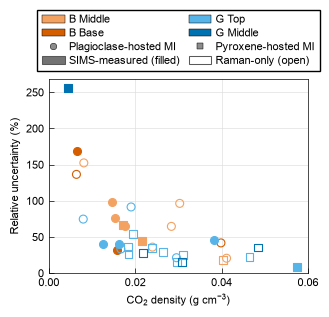

In [23]:
sample_handles = [
    Patch(
        facecolor=SAMPLE_COLORS[key],
        edgecolor='black',
        linewidth=0.35,
        label=SAMPLE_LABELS[key],
    )
    for key in ['74D', '75', '74A', '76A']
]

phase_handles = [
    Line2D(
        [0], [0],
        marker=PHASE_MARKERS[key],
        linestyle='none',
        markersize=4.7,
        markerfacecolor='0.55',
        markeredgecolor='black',
        markeredgewidth=0.35,
        label=PHASE_LABELS[key],
    )
    for key in PHASE_MARKERS
]

method_handles = [
    Patch(
        facecolor='0.45',
        edgecolor='0.35',
        linewidth=0.75,
        label='SIMS-measured (filled)',
    ),
    Patch(
        facecolor='none',
        edgecolor='0.35',
        linewidth=0.75,
        label='Raman-only (open)',
    ),
]

linear_figure, linear_axis = plt.subplots(
    figsize=(FIGURE_WIDTH_IN, FIGURE_HEIGHT_IN)
)
linear_figure.subplots_adjust(
    left=0.20,
    right=0.93,
    bottom=0.16,
    top=0.70,
)

for sample_key, color in SAMPLE_COLORS.items():
    for phase, marker in PHASE_MARKERS.items():
        subset = retained.loc[
            retained['sample_key'].eq(sample_key)
            & retained['mineral_phase'].eq(phase)
        ]

        for has_sims_measurement in (True, False):
            points = subset.loc[
                subset['has_sims_measurement'].eq(has_sims_measurement)
            ]
            if points.empty:
                continue

            style = dict(SCATTER_STYLES[{'o': 'plag', 's': 'pxy'}[marker]])
            style.update(edgecolors=color, linewidths=0.8)
            linear_axis.scatter(
                points['Density g/cm3'],
                points['relative_density_error_pct'],
                facecolors=color if has_sims_measurement else 'none',
                alpha=1.0,
                zorder=3,
                **style,
            )

linear_axis.set_xscale('linear')
linear_axis.set_yscale('linear')
linear_axis.set_xlim(0, 0.06)
linear_axis.set_xticks([0.00, 0.02, 0.04, 0.06])
linear_axis.set_ylim(bottom=0)
linear_axis.set_xlabel('CO$_2$ density (g cm$^{-3}$)')
linear_axis.set_ylabel('Relative uncertainty (%)')
linear_axis.set_axisbelow(True)
linear_axis.grid(
    True, which='major', axis='both',
    color='#D9D9D9', linewidth=0.4, linestyle='-',
)
linear_axis.minorticks_off()
linear_axis.tick_params(which='major', direction='in')
for spine in linear_axis.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.5)

# Arrange the same eight legend entries in four paired rows.
legend_rows = [
    sample_handles[:2],
    sample_handles[2:],
    phase_handles,
    method_handles,
]
legend_handles = [
    legend_rows[row][column]
    for column in range(2)
    for row in range(4)
]

linear_legend = linear_axis.legend(
    handles=legend_handles,
    loc='lower center',
    bbox_to_anchor=(0.5, 1.01),
    ncol=2,
    frameon=True,
    fancybox=False,
    framealpha=1,
    edgecolor='black',
    columnspacing=0.8,
    handletextpad=0.4,
    labelspacing=0.3,
    borderpad=0.45,
)

PDF_PATH = OUTPUT_DIRECTORY / 'Figure_S02_Raman_Density_Error_linear.pdf'
PNG_PATH = OUTPUT_DIRECTORY / 'Figure_S02_Raman_Density_Error_linear.png'
SVG_PATH = OUTPUT_DIRECTORY / 'Figure_S02_Raman_Density_Error_linear.svg'

linear_figure.savefig(
    PDF_PATH,
    format='pdf',
    dpi=EXPORT_DPI,
    facecolor='white',
    transparent=False,
)
linear_figure.savefig(
    PNG_PATH,
    format='png',
    dpi=EXPORT_DPI,
    facecolor='white',
    transparent=False,
)
linear_figure.savefig(
    SVG_PATH,
    format='svg',
    dpi=EXPORT_DPI,
    facecolor='white',
    transparent=False,
)

linear_paths = {
    'pdf': PDF_PATH,
    'png': PNG_PATH,
    'svg': SVG_PATH,
}

for output_path in linear_paths.values():
    if not output_path.is_file() or output_path.stat().st_size == 0:
        raise IOError(f'Expected export was not created: {output_path}')
    print(f'Saved: {output_path}')

display(linear_figure)
plt.close(linear_figure)

## Final checks

In [24]:
# Keep these checks short and focused on the plotted values.
if retained.empty:
    raise ValueError('No rows remain for plotting.')

if not retained['Density g/cm3'].gt(0).all():
    raise ValueError('All plotted densities must be greater than zero.')

if not np.isfinite(
    retained[['Density g/cm3', 'σ Density g/cm3', 'relative_density_error_pct']]
).all().all():
    raise ValueError('The plotted density and uncertainty values must be finite.')

calculated_relative_uncertainty = (
    100 * retained['σ Density g/cm3'] / retained['Density g/cm3']
)
if not np.allclose(
    retained['relative_density_error_pct'],
    calculated_relative_uncertainty,
):
    raise ValueError('Relative uncertainty was not calculated as 100 × σ / density.')

print(f'Final checks passed for {len(retained)} plotted records.')

Final checks passed for 35 plotted records.
